# Lesson 2: Simple baselines to beat

Before building a neural network, find out what simple methods achieve. They show what "good" means for this data, and they are honest competitors: if a polynomial did as well as a network, you would not need the network.

Three baselines, from crude to reasonable:

1. The mean: predict the training-set average for every model.
2. Polynomials: a smooth global fit, solved exactly by least squares.
3. Nearest neighbours: average the closest training models. This is close to what interpolating in a precomputed table does.

Every method works on the transformed data from Lesson 1 (inputs in [-1, 1], standardized outputs). Errors are always reported in dex, after undoing the output transform.

In [1]:
# 1. Let Python find the emulator package
import sys

sys.path.insert(0, "..")

# 2. Imports
import json
import time

import matplotlib.pyplot as plt
import numpy as np

from emulator import baselines, data, evaluate
from emulator.evaluate import PALETTE

# 3. Load the grid, split it and transform it (as in Lesson 1)
grid = data.load_grid("../training_250k.h5")
inputs, outputs, output_names = grid["inputs"], grid["outputs"], grid["output_names"]
indices = data.split_from_labels(grid["split"])
train, val = indices["train"], indices["val"]

input_transform = data.fit_input_transform(inputs[train])
output_transform = data.fit_output_transform(outputs[train])
x_train = data.transform_inputs(inputs[train], input_transform)
x_val = data.transform_inputs(inputs[val], input_transform)
y_train = data.transform_outputs(outputs[train], output_transform)
y_val_log10 = outputs[val]

## How we score an emulator

For each output we compute |prediction - truth| in dex over the validation models, then take the median (a typical error) and the 99th percentile (the bad cases). Averaging those over the 19 outputs gives two numbers per method.

We only count a model for a species where the true **or** predicted abundance is above 1e-12. Below that no spectrum can tell values apart, so errors there do not matter. Taking the larger of the two values catches both a species that the emulator misses and one that it invents.

In [2]:
# 1. A dictionary to collect every method's scores
scores = {}

## 1. The mean

In [3]:
# 1. Predict the training mean everywhere, then undo the output transform
y_pred = baselines.predict_mean(y_train, len(val))
log10_pred = data.inverse_transform_outputs(y_pred, output_transform)

# 2. Score it
scores["mean"] = evaluate.summary_errors(y_val_log10, log10_pred)
print(scores["mean"])

{'median': 9.513517842847824, 'p99': 15.398110843113177}


The errors are several dex, because the outputs themselves vary by that much across the grid, and any useful emulator must do far better.

## 2. Polynomials

A polynomial of degree *d* in six inputs is a weighted sum of every product of inputs up to total degree *d* (1, x1, x2, x1*x1, x1*x2 and so on). The weights enter linearly, so the best weights have an exact solution, the least-squares one: no iterations, no learning rate. The price is the number of terms, which grows quickly with the degree.

In [4]:
# 1. Fit polynomials of increasing degree and score them on both sets
degrees = [1, 2, 3, 4, 5]
polynomial_scores = {"train": [], "val": []}
y_train_log10 = outputs[train]

for degree in degrees:
    start = time.perf_counter()
    coefficients = baselines.fit_polynomial(x_train, y_train, degree)
    seconds = time.perf_counter() - start

    # 1a. Validation and training errors in dex
    for name, x, truth in [
        ("val", x_val, y_val_log10),
        ("train", x_train, y_train_log10),
    ]:
        y_pred = baselines.predict_polynomial(x, coefficients, degree)
        log10_pred = data.inverse_transform_outputs(y_pred, output_transform)
        polynomial_scores[name].append(evaluate.summary_errors(truth, log10_pred))

    scores[f"polynomial, degree {degree}"] = polynomial_scores["val"][-1]
    print(
        f"degree {degree}: {coefficients.shape[0]:4d} terms per output, fit in {seconds:5.1f} s, "
        f"validation median {polynomial_scores['val'][-1]['median']:.3f} dex, "
        f"99% {polynomial_scores['val'][-1]['p99']:.2f} dex"
    )

degree 1:    7 terms per output, fit in   0.1 s, validation median 3.359 dex, 99% 8.09 dex


degree 2:   28 terms per output, fit in   0.2 s, validation median 2.599 dex, 99% 7.08 dex


degree 3:   84 terms per output, fit in   0.7 s, validation median 1.459 dex, 99% 4.64 dex


degree 4:  210 terms per output, fit in   2.0 s, validation median 0.908 dex, 99% 3.62 dex


degree 5:  462 terms per output, fit in   5.4 s, validation median 0.719 dex, 99% 3.03 dex


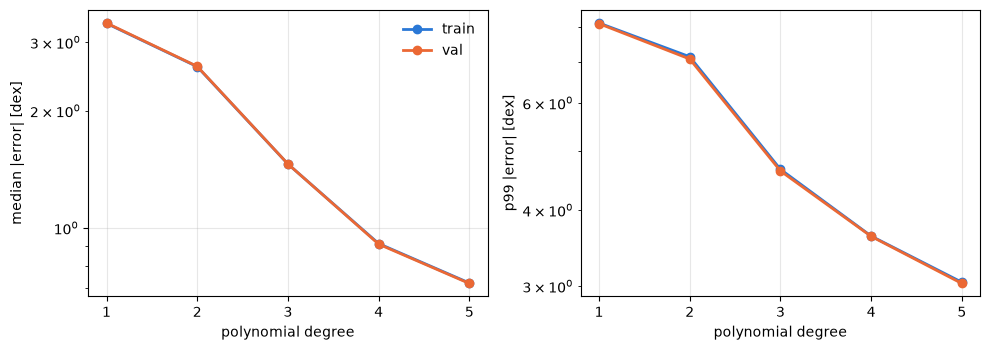

In [5]:
# 1. Error against degree, training and validation
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, statistic in zip(axes, ["median", "p99"]):
    for colour, name in zip(PALETTE, ["train", "val"]):
        values = [score[statistic] for score in polynomial_scores[name]]
        ax.plot(degrees, values, "o-", color=colour, lw=2, label=name)
    ax.set(
        xlabel="polynomial degree", ylabel=f"{statistic} |error| [dex]", yscale="log"
    )
    ax.set_xticks(degrees)
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

Training and validation errors are almost identical. With 200,000 models and a few hundred coefficients, the polynomial cannot memorize the training set, so its error comes from its limited flexibility rather than from a lack of data. This is called *underfitting*, and its opposite, *overfitting*, shows up as a training error well below the validation error.

The gains also shrink with every degree, because a polynomial is global: every term is felt everywhere, so to bend sharply at a condensation cliff in one corner of the input space it has to wiggle everywhere else. Here is the degree-5 fit for TiO:

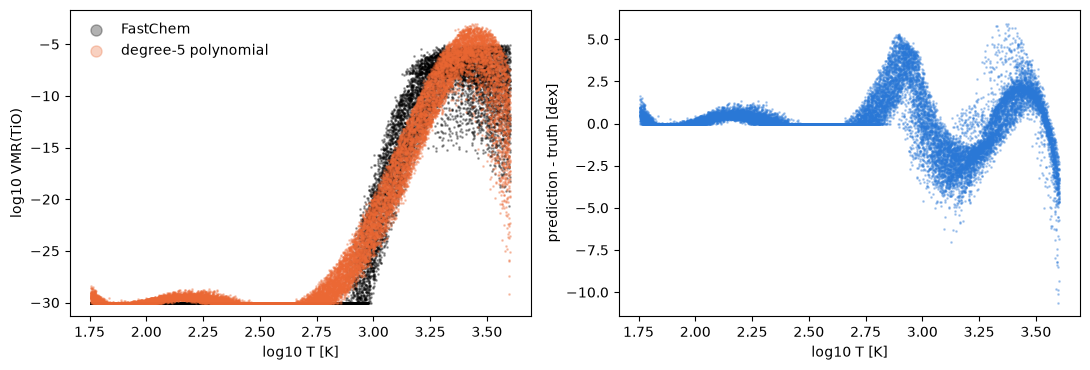

In [6]:
# 1. Degree-5 residuals for TiO against temperature
coefficients = baselines.fit_polynomial(x_train, y_train, 5)
log10_pred = data.inverse_transform_outputs(
    baselines.predict_polynomial(x_val, coefficients, 5), output_transform
)
column = output_names.index("TiO")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(
    inputs[val, 0],
    y_val_log10[:, column],
    s=1,
    color="black",
    alpha=0.3,
    label="FastChem",
    rasterized=True,
)
axes[0].scatter(
    inputs[val, 0],
    log10_pred[:, column],
    s=1,
    color=PALETTE[1],
    alpha=0.3,
    label="degree-5 polynomial",
    rasterized=True,
)
axes[0].set(xlabel="log10 T [K]", ylabel="log10 VMR(TiO)")
axes[0].legend(frameon=False, markerscale=8)
axes[1].scatter(
    inputs[val, 0],
    log10_pred[:, column] - y_val_log10[:, column],
    s=1,
    color=PALETTE[0],
    alpha=0.3,
    rasterized=True,
)
axes[1].set(xlabel="log10 T [K]", ylabel="prediction - truth [dex]")
fig.tight_layout()
plt.show()

The polynomial cannot follow the cliff onto the floor, and it overshoots on both sides of it.

## 3. Nearest neighbours

Nearest neighbours takes the opposite approach: there is no global formula, and the prediction is an average of the k training models closest to the requested point, each weighted by 1/distance. This is close to interpolating in a precomputed table, which is how most retrieval codes handle equilibrium chemistry today.

In [7]:
# 1. k nearest neighbours for a few values of k
for k in [1, 8, 32]:
    start = time.perf_counter()
    y_pred = baselines.predict_nearest_neighbours(x_train, y_train, x_val, k=k)
    seconds = time.perf_counter() - start
    log10_pred = data.inverse_transform_outputs(y_pred, output_transform)
    scores[f"nearest neighbours, k={k}"] = evaluate.summary_errors(
        y_val_log10, log10_pred
    )
    print(
        f"k={k:2d}: median {scores[f'nearest neighbours, k={k}']['median']:.3f} dex, "
        f"99% {scores[f'nearest neighbours, k={k}']['p99']:.2f} dex   ({seconds:.1f} s for {len(val)} points)"
    )

k= 1: median 0.374 dex, 99% 5.69 dex   (0.2 s for 25000 points)


k= 8: median 0.291 dex, 99% 3.01 dex   (0.5 s for 25000 points)


k=32: median 0.398 dex, 99% 2.90 dex   (1.0 s for 25000 points)


With k = 8, nearest neighbours beats every polynomial without fitting anything. Whether computing a bigger grid is a plan depends on how fast this error falls as the number of training models grows:

error ~ N^-0.32: four times more models gives 0.64 times the error


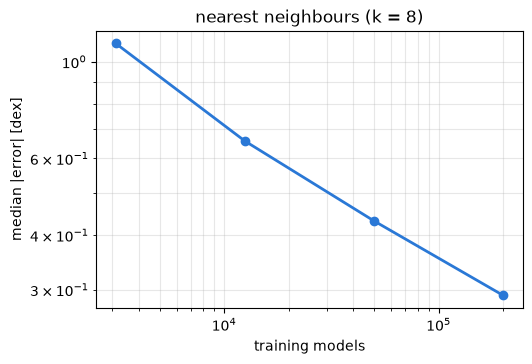

In [8]:
# 1. Nearest-neighbour error for training sets of increasing size
rng = np.random.default_rng(0)
sizes = [3125, 12500, 50000, 200000]
learning_curve = []
for size in sizes:
    subset = rng.choice(len(train), size=size, replace=False)
    y_pred = baselines.predict_nearest_neighbours(
        x_train[subset], y_train[subset], x_val, k=8
    )
    log10_pred = data.inverse_transform_outputs(y_pred, output_transform)
    learning_curve.append(evaluate.summary_errors(y_val_log10, log10_pred)["median"])

# 2. Slope of log(error) against log(size)
slope = np.polyfit(np.log10(sizes), np.log10(learning_curve), 1)[0]
print(
    f"error ~ N^{slope:.2f}: four times more models gives {4 ** slope:.2f} times the error"
)

# 3. Plot
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.loglog(sizes, learning_curve, "o-", color=PALETTE[0], lw=2)
ax.set(
    xlabel="training models",
    ylabel="median |error| [dex]",
    title="nearest neighbours (k = 8)",
)
ax.grid(alpha=0.3, which="both")
plt.show()

The error falls roughly as N^(-1/3). In six dimensions the spacing between neighbouring models shrinks only like N^(-1/6), and in smooth regions this kind of interpolation has an error that goes as the spacing squared, so N^(-2/6) = N^(-1/3). Halving the error takes 2^3 = 8 times more models, and a ten times smaller error takes a thousand times more. Tables get big and slow long before they get accurate. This is the problem the emulator team set out to solve.

## Summary

In [9]:
# 1. Print every method's scores
for name, score in scores.items():
    print(f"{name:26s} median {score['median']:.4f} dex   99% {score['p99']:.3f} dex")

# 2. Save them for the next lessons to compare against
with open("../runs/baseline_scores.json", "w") as handle:
    json.dump(scores, handle, indent=1)

mean                       median 9.5135 dex   99% 15.398 dex
polynomial, degree 1       median 3.3587 dex   99% 8.094 dex
polynomial, degree 2       median 2.5986 dex   99% 7.081 dex
polynomial, degree 3       median 1.4586 dex   99% 4.636 dex
polynomial, degree 4       median 0.9077 dex   99% 3.619 dex
polynomial, degree 5       median 0.7193 dex   99% 3.029 dex
nearest neighbours, k=1    median 0.3736 dex   99% 5.694 dex
nearest neighbours, k=8    median 0.2910 dex   99% 3.008 dex
nearest neighbours, k=32   median 0.3979 dex   99% 2.900 dex


These numbers are the bar for the neural network in Lessons 3 and 4.

## Exercises

1. Fit a degree-6 polynomial. How many terms, how long, and how much better?
2. Try k = 4 and k = 16. Why does the error get worse for large k?
3. Nearest neighbours measures distance in the scaled inputs, so all six inputs count equally. Multiply the temperature column by 2 (in both `x_train` and `x_val`) before the search. Does weighting temperature more help?
4. Time `baselines.predict_nearest_neighbours` for a single point. Would it be fast enough inside a retrieval that calls it a million times?